<a href="https://colab.research.google.com/github/ErrPeppe/OhnomiTools/blob/main/notebooks/03_network_motifs_null_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 3 — Topologia delle Reti Regolatorie, Motivi Multistrato e Modelli Nulli Microcanonici

## Introduzione Biologica, Fisica e Metodi Matematici

### 1. Dai Dati Genomici alla Fisica delle Reti Regolatorie
Nella Fase 2 è stato dimostrato che le coppie di geni ohnologhi (WGD) ospitano coppie di lncRNA intragenici con orientamento conservato significativamente più spesso delle duplicazioni locali antiche (SSD), anche dopo aver rimosso il confondente della lunghezza dei geni host ($\text{OR}_{\text{adj}} = 1{,}28$ nel Ramo A puro; picco $\text{OR}_{\text{adj}} = 1{,}41$ nell'Intersezione $A \cap B$ alla soglia $\ge 15.\,\text{Amniota}$).

In questa fase si passa dalla genomica posizionale alla **fisica delle reti complesse**, estendendo ai lncRNA l'impianto quantitativo sviluppato per fattori di trascrizione, microRNA e reti di interazione proteina–proteina (Mottes et al., *PLOS Comput. Biol.* 2021; Agasso et al., *PLOS Comput. Biol.* 2025). La domanda centrale è se la conservazione selettiva degli ohno-lncRNA si traduca in una **firma topologica specifica** nei network molecolari:
* **Superamento del solo modello *ceRNA*:** tenendo conto del dibattito aperto in letteratura sull'effettiva rilevanza fisiologica del meccanismo *ceRNA* (competizione per il legame ai miRNA) come funzione generale dei lncRNA, l'analisi pone al centro il **Layer fisico lncRNA–RBP** (772.745 siti di legame sperimentali eCLIP/CLIP-seq di LncBook v2.0), integrato con la rete proteina–proteina ad alta confidenza **STRING v12.0** (`combined_score >= 700` e verifica di robustezza a `>= 960`). In parallelo viene comunque analizzato il **Layer lncRNA–miRNA** (tripla intersezione termodinamica *miRanda* $\cap$ *TargetScan* $\cap$ *RNAhybrid*) per un confronto diretto.
* **Continuità sulle Tre Vie Analitiche:** tutte le metriche vengono valutate in parallelo su **Via 1 (Ramo A puro)**, **Via 2 (Intersezione $A \cap B$, $\ge 15.\,\text{Amniota}$)** e **Via 3 (Ramo B, coorte `17. Euteleostomi` inclusi i 635 lincRNA intergenici)**.

### 2. Formulazione Matematica delle Metriche e dei Motivi di Rete
Ciascun layer è rappresentato come un grafo bipartito non pesato a livello di gene $G = (U, V, E)$, dove $U$ è l'insieme dei geni lncRNA (`HSALNG`), $V$ l'insieme dei bersagli molecolari (proteine RBP oppure miRNA) e $N(u) = \{t \in V : (u, t) \in E\}$ è il vicinato del lncRNA $u$ di grado $k_u = |N(u)|$.

Per ogni coppia di lncRNA duplicati $(u, w)$ presenti in rete ($k_u > 0, k_w > 0$) vengono calcolati:
1. **V-Motif (co-targeting / ridondanza regolatoria):** numero di bersagli condivisi $V(u, w) = |N(u) \cap N(w)|$.
2. **Coefficiente di Sørensen–Dice** (Mottes et al., 2021; Agasso et al., 2025) e **Indice di Jaccard**:
   $$S_{\text{SD}}(u, w) = \frac{2\,|N(u) \cap N(w)|}{k_u + k_w}, \qquad J(u, w) = \frac{|N(u) \cap N(w)|}{|N(u) \cup N(w)|}$$
3. **Asimmetria di Grado Normalizzata:** $\tilde{\Delta}k(u, w) = \frac{|k_u - k_w|}{k_u + k_w} \in [0, 1]$, che distingue la conservazione simmetrica ($\tilde{\Delta}k \to 0$) dalla specializzazione/neofunzionalizzazione asimmetrica ($\tilde{\Delta}k \to 1$).
4. **Bifans e PPI-Bifans:** dato l'insieme dei bersagli condivisi $C = N(u) \cap N(w)$, il numero di *Simple Bifans* è $\binom{|C|}{2}$; restringendo le coppie $\{t_a, t_b\} \subset C$ ai bersagli che interagiscono fisicamente nella rete proteica **STRING** ($E_{\text{PPI}}$) si ottengono i **PPI-Bifans** (test diretto dell'ipotesi del bilanciamento del dosaggio su complessi proteici), mentre restringendole a coppie di proteine a loro volta paraloghe si ottengono i **Duplicated Bifans**.
5. **PPI-Delta (a singolo lncRNA, Via 3):** per un singolo lncRNA $u$, numero di coppie di RBP legate da $u$ che interagiscono fisicamente tra loro in STRING.

### 3. Modello Nullo Microcanonico (Maslov–Sneppen) e Z-score
Per escludere che l'abbondanza di motivi sia un artefatto della distribuzione di grado (*hub bias*), viene generato un ensemble microcanonico di $N_{\text{null}}$ reti randomizzate mediante **scambio di doppi archi (*double-edge swap*) di Maslov–Sneppen**, che preserva **esattamente** il grado di ogni singolo lncRNA ($k_u$) e di ogni singolo bersaglio ($k_t$). La significatività statistica di ogni osservabile $n_{\text{obs}}$ è quantificata dallo **Z-score**:
$$Z = \frac{n_{\text{obs}} - \langle n_{\text{null}} \rangle}{\sigma_{\text{null}}}$$
adottando come riferimento la soglia stringente $|Z| > 5$ usata in Mottes et al. (2021), affiancata dal $p$-value empirico.

## 1. Setup dell'Ambiente e Integrazione Automatica di STRING v12.0
Installazione dell'ultima versione di `OhnomiTools` (con `stats.py` e `network.py`), conversione in Silver degli eventuali file aggiunti in `bronze/` (`sprotein`, `methylation`) e download automatico della rete proteina–proteina umana **STRING v12.0** (`combined_score >= 700`).

In [ ]:
!pip install -q --no-cache-dir git+https://github.com/ErrPeppe/OhnomiTools.git
from ohnomitools import setup_colab
from ohnomitools.fetcher import DataIngestionPipeline

PATHS = setup_colab(show_status=False)
pipeline = DataIngestionPipeline(paths=PATHS)
_ = pipeline.run_all(include_string=True, force_rebuild=False)
PATHS.print_status()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
shape: (30, 5)
┌──────────┬─────────────────────────────────┬──────────┬─────────┬────────────────────────────────┐
│ Layer    ┆ Dataset                         ┆ Presente ┆ Size_MB ┆ Path                           │
│ ---      ┆ ---                             ┆ ---      ┆ ---     ┆ ---                            │
│ str      ┆ str                             ┆ str      ┆ f64     ┆ str                            │
╞══════════╪═════════════════════════════════╪══════════╪═════════╪════════════════════════════════╡
│ Bronze   ┆ LncBook v2.0 GTF                ┆ SI       ┆ 15.2    ┆ bronze/lncRNA_LncBookv2.0_GRCh │
│          ┆                                 ┆          ┆         ┆ 38.gtf.gz                      │
│ Bronze   ┆ LncBook v2.0 FASTA              ┆ SI       ┆ 107.47  ┆ bronze/lncRNA_LncBookv2.0.fa.g │
│          ┆                              

## 2. Costruzione dei Grafi Bipartiti e Analisi delle Distribuzioni di Grado ($k_{\text{out}}$) sulle 3 Vie
Deduplicazione a livello di gene dei due layer di interazione (`RBP` e `miRNA`), mappatura degli archi fisici **STRING** sulle proteine RBP e confronto statistico (test di Kolmogorov–Smirnov e Mann–Whitney U) della connettività $k_{\text{out}}$ tra coorti WGD, SSD antiche, `17. Euteleostomi` (intragenici vs lincRNA intergenici) e controlli recenti (`12. Eutheria`, `1. Homo`).

In [ ]:
import polars as pl
from ohnomitools.network import NetworkMotifAnalyzer

net_analyzer = NetworkMotifAnalyzer(paths=PATHS)

# 1. Costruzione dei due layer (RBP con STRING >= 700 e miRNA tripla intersezione)
net_rbp = net_analyzer.build_network(layer="rbp", ppi_min_score=700)
net_mirna = net_analyzer.build_network(layer="mirna")

# 2. Distribuzioni di grado k_out su tutte e 3 le Vie
deg_rbp = net_analyzer.analyze_degree_distributions(net_rbp)
deg_mirna = net_analyzer.analyze_degree_distributions(net_mirna)

with pl.Config(tbl_rows=15, tbl_cols=12, fmt_str_lengths=40):
    print("=== LAYER RBP — GRADI k_out SULLE 3 VIE ===")
    print(deg_rbp["summary"])
    print("\n=== LAYER RBP — TEST KS & MANN-WHITNEY ===")
    print(deg_rbp["tests"])

    print("\n=== LAYER miRNA — GRADI k_out SULLE 3 VIE ===")
    print(deg_mirna["summary"])
    print("\n=== LAYER miRNA — TEST KS & MANN-WHITNEY ===")
    print(deg_mirna["tests"])

=== LAYER RBP — GRADI k_out SULLE 3 VIE ===
shape: (10, 10)
┌───────┬──────────┬──────────┬──────────┬──────────┬──────────┬─────────┬─────────┬───────┬───────┐
│ Layer ┆ Via      ┆ Coorte   ┆ N_geni_c ┆ N_in_ret ┆ Copertur ┆ k_media ┆ k_media ┆ k_p90 ┆ k_max │
│ ---   ┆ ---      ┆ ---      ┆ oorte    ┆ e        ┆ a_pct    ┆ na      ┆ ---     ┆ ---   ┆ ---   │
│ str   ┆ str      ┆ str      ┆ ---      ┆ ---      ┆ ---      ┆ ---     ┆ f64     ┆ f64   ┆ i64   │
│       ┆          ┆          ┆ i64      ┆ i64      ┆ f64      ┆ f64     ┆         ┆       ┆       │
╞═══════╪══════════╪══════════╪══════════╪══════════╪══════════╪═════════╪═════════╪═══════╪═══════╡
│ RBP   ┆ Via 1    ┆ WGD_intr ┆ 10480    ┆ 89       ┆ 0.85     ┆ 2.0     ┆ 3.551   ┆ 9.2   ┆ 29    │
│       ┆ (Ramo A) ┆ agenic   ┆          ┆          ┆          ┆         ┆         ┆       ┆       │
│ RBP   ┆ Via 1    ┆ SSD_anci ┆ 22024    ┆ 197      ┆ 0.89     ┆ 2.0     ┆ 3.391   ┆ 7.0   ┆ 42    │
│       ┆ (Ramo A) ┆ ent_intr ┆

## 3. Layer Fisico lncRNA–RBP (+ STRING): Ridondanza, Motivi e Modelli Nulli di Maslov–Sneppen
Esecuzione dell'ensemble microcanonico di Maslov–Sneppen (`n_null=100` repliche accelerate in Numba) sia sulla **Via 1 (Ramo A puro)** sia sulla **Via 2 (Intersezione $A \cap B$, $\ge 15.\,\text{Amniota}$)**, confrontando **WGD** e **SSD antiche** su V-motifs, Sørensen–Dice, Simple Bifans, Duplicated Bifans e **PPI-Bifans**.

In [ ]:
# Via 2 (Intersezione A ∩ B — Gold Standard)
res_rbp_via2 = net_analyzer.analyze_pair_motifs_and_null_models(
    net_rbp, lane="via2", n_null=100, seed=42
)

# Via 1 (Ramo A puro — campionamento a 25.000 coppie SSD per velocità del modello nullo)
res_rbp_via1 = net_analyzer.analyze_pair_motifs_and_null_models(
    net_rbp, lane="via1", n_null=100, seed=42, max_ssd_pairs_for_null=25000
)

with pl.Config(tbl_rows=20, tbl_cols=14, fmt_str_lengths=35):
    print("=== LAYER RBP | VIA 2 (A ∩ B) — Z-SCORE MASLOV-SNEPPEN ===")
    print(res_rbp_via2["z_summary"])
    print("\n=== LAYER RBP | VIA 2 (A ∩ B) — WGD vs SSD (KS & MW) ===")
    print(res_rbp_via2["wgd_vs_ssd"])

    print("\n=== LAYER RBP | VIA 1 (RAMO A) — Z-SCORE MASLOV-SNEPPEN ===")
    print(res_rbp_via1["z_summary"])
    print("\n=== LAYER RBP | VIA 1 (RAMO A) — WGD vs SSD (KS & MW) ===")
    print(res_rbp_via1["wgd_vs_ssd"])

=== LAYER RBP | VIA 2 (A ∩ B) — Z-SCORE MASLOV-SNEPPEN ===
shape: (5, 13)
┌─────┬─────┬─────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Lay ┆ Via ┆ Tip ┆ Coppie ┆ Coppi ┆ Frac_ ┆ Frac_ ┆ Metri ┆ Osser ┆ Null_ ┆ Null_ ┆ Z_sco ┆ p_emp │
│ er  ┆ --- ┆ o   ┆ _total ┆ e_in_ ┆ V_pos ┆ PPI_B ┆ ca    ┆ vato  ┆ Mean  ┆ Std   ┆ re    ┆ irico │
│ --- ┆ str ┆ --- ┆ i      ┆ rete  ┆ _pct  ┆ ifan_ ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ str ┆     ┆ str ┆ ---    ┆ ---   ┆ ---   ┆ pos_p ┆ str   ┆ f64   ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
│     ┆     ┆     ┆ i64    ┆ i64   ┆ f64   ┆ ct    ┆       ┆       ┆       ┆       ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆ ---   ┆       ┆       ┆       ┆       ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆ f64   ┆       ┆       ┆       ┆       ┆       ┆       │
╞═════╪═════╪═════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ RBP ┆ via ┆ SSD

## 4. Via 3 (Ramo B `17. Euteleostomi`): Motivi PPI-Delta su Singoli lncRNA e Sensibilità STRING (`>= 960`)
Valutazione dei motivi **PPI-Delta** a singolo gene (stile Agasso et al., Fig. 3D) per testare se i lncRNA ancestrali legano preferenzialmente coppie di proteine RBP che formano complessi fisici, distinguendo gli intragenici in host WGD dai **lincRNA intergenici**, seguita dal controllo di robustezza sulla soglia ultra-stringente di STRING (`combined_score >= 960`).

In [ ]:
# Via 3 (Ramo B): PPI-Delta su STRING >= 700
df_via3_delta = net_analyzer.analyze_via3_ppi_delta(net_rbp, n_null=100, seed=123)
print("=== LAYER RBP | VIA 3 (RAMO B) — MOTIVI PPI-DELTA (STRING >= 700) ===")
with pl.Config(tbl_rows=10, tbl_cols=12, fmt_str_lengths=35):
    print(df_via3_delta)

# Controllo di robustezza su STRING >= 960 (soglia ultra-stringente stile Agasso et al.)
net_rbp_960 = net_analyzer.build_network(layer="rbp", ppi_min_score=960)
res_rbp_via2_960 = net_analyzer.analyze_pair_motifs_and_null_models(
    net_rbp_960, lane="via2", n_null=100, seed=42
)
print("\n=== CONTROLLO ROBUSTEZZA STRING >= 960 | VIA 2 (A ∩ B) ===")
with pl.Config(tbl_rows=15, tbl_cols=14, fmt_str_lengths=35):
    print(res_rbp_via2_960["z_summary"].filter(pl.col("Metrica") == "PPI-Bifans (STRING)"))

=== LAYER RBP | VIA 3 (RAMO B) — MOTIVI PPI-DELTA (STRING >= 700) ===
shape: (5, 10)
┌───────┬──────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┐
│ Layer ┆ Coorte_V ┆ N_in_re ┆ Frac_PP ┆ Media_P ┆ Totale_ ┆ Null_Me ┆ Null_St ┆ Z_score ┆ p_empir │
│ ---   ┆ ia3      ┆ te      ┆ I_Delta ┆ PI_Delt ┆ osserva ┆ an      ┆ d       ┆ ---     ┆ ico     │
│ str   ┆ ---      ┆ ---     ┆ _pos_pc ┆ a_per_g ┆ to      ┆ ---     ┆ ---     ┆ f64     ┆ ---     │
│       ┆ str      ┆ i64     ┆ t       ┆ ene     ┆ ---     ┆ f64     ┆ f64     ┆         ┆ f64     │
│       ┆          ┆         ┆ ---     ┆ ---     ┆ i64     ┆         ┆         ┆         ┆         │
│       ┆          ┆         ┆ f64     ┆ f64     ┆         ┆         ┆         ┆         ┆         │
╞═══════╪══════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╡
│ RBP   ┆ Eut_intr ┆ 9       ┆ 33.33   ┆ 6.889   ┆ 62      ┆ 22.15   ┆ 6.6     ┆ 6.04    ┆ 0.0198  │
│     


=== CONTROLLO ROBUSTEZZA STRING >= 960 | VIA 2 (A ∩ B) ===
shape: (1, 13)
┌─────┬─────┬─────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Lay ┆ Via ┆ Tip ┆ Coppie ┆ Coppi ┆ Frac_ ┆ Frac_ ┆ Metri ┆ Osser ┆ Null_ ┆ Null_ ┆ Z_sco ┆ p_emp │
│ er  ┆ --- ┆ o   ┆ _total ┆ e_in_ ┆ V_pos ┆ PPI_B ┆ ca    ┆ vato  ┆ Mean  ┆ Std   ┆ re    ┆ irico │
│ --- ┆ str ┆ --- ┆ i      ┆ rete  ┆ _pct  ┆ ifan_ ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ str ┆     ┆ str ┆ ---    ┆ ---   ┆ ---   ┆ pos_p ┆ str   ┆ f64   ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
│     ┆     ┆     ┆ i64    ┆ i64   ┆ f64   ┆ ct    ┆       ┆       ┆       ┆       ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆ ---   ┆       ┆       ┆       ┆       ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆ f64   ┆       ┆       ┆       ┆       ┆       ┆       │
╞═════╪═════╪═════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ RBP ┆ via ┆ SS

## 5. Layer lncRNA–miRNA (Tripla Intersezione): Confronto Parallelo su Via 1 e Via 2
Replica esatta dell'analisi di ridondanza regolatoria e dei modelli nulli di Maslov–Sneppen sul layer *ceRNA* (lncRNA–miRNA di LncBook v2.0), per confrontare direttamente la firma topologica delle interazioni RNA–RNA con quella del layer fisico RNA–proteina.

In [ ]:
res_mir_via2 = net_analyzer.analyze_pair_motifs_and_null_models(
    net_mirna, lane="via2", n_null=100, seed=42
)
res_mir_via1 = net_analyzer.analyze_pair_motifs_and_null_models(
    net_mirna, lane="via1", n_null=100, seed=42, max_ssd_pairs_for_null=25000
)

with pl.Config(tbl_rows=20, tbl_cols=14, fmt_str_lengths=35):
    print("=== LAYER miRNA | VIA 2 (A ∩ B) — Z-SCORE MASLOV-SNEPPEN ===")
    print(res_mir_via2["z_summary"])
    print("\n=== LAYER miRNA | VIA 2 (A ∩ B) — WGD vs SSD (KS & MW) ===")
    print(res_mir_via2["wgd_vs_ssd"])

    print("\n=== LAYER miRNA | VIA 1 (RAMO A) — Z-SCORE MASLOV-SNEPPEN ===")
    print(res_mir_via1["z_summary"])

=== LAYER miRNA | VIA 2 (A ∩ B) — Z-SCORE MASLOV-SNEPPEN ===
shape: (6, 13)
┌─────┬─────┬─────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Lay ┆ Via ┆ Tip ┆ Coppie ┆ Coppi ┆ Frac_ ┆ Frac_ ┆ Metri ┆ Osser ┆ Null_ ┆ Null_ ┆ Z_sco ┆ p_emp │
│ er  ┆ --- ┆ o   ┆ _total ┆ e_in_ ┆ V_pos ┆ PPI_B ┆ ca    ┆ vato  ┆ Mean  ┆ Std   ┆ re    ┆ irico │
│ --- ┆ str ┆ --- ┆ i      ┆ rete  ┆ _pct  ┆ ifan_ ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ str ┆     ┆ str ┆ ---    ┆ ---   ┆ ---   ┆ pos_p ┆ str   ┆ f64   ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
│     ┆     ┆     ┆ i64    ┆ i64   ┆ f64   ┆ ct    ┆       ┆       ┆       ┆       ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆ ---   ┆       ┆       ┆       ┆       ┆       ┆       │
│     ┆     ┆     ┆        ┆       ┆       ┆ f64   ┆       ┆       ┆       ┆       ┆       ┆       │
╞═════╪═════╪═════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ MIR ┆ via ┆ W

## 6. Visualizzazione dei Risultati (Export `gold/`) ed Estrazione dei Top Casi Studio WGD
Generazione delle figure comparative a 3 pannelli (salvate in `.png` 300 dpi e `.pdf` vettoriale in `gold/`) per entrambi i layer e stampa delle prime 10 coppie WGD della Via 2 ($A \cap B$) ordinate per numero di **PPI-Bifans** e indice di **Sørensen–Dice**.

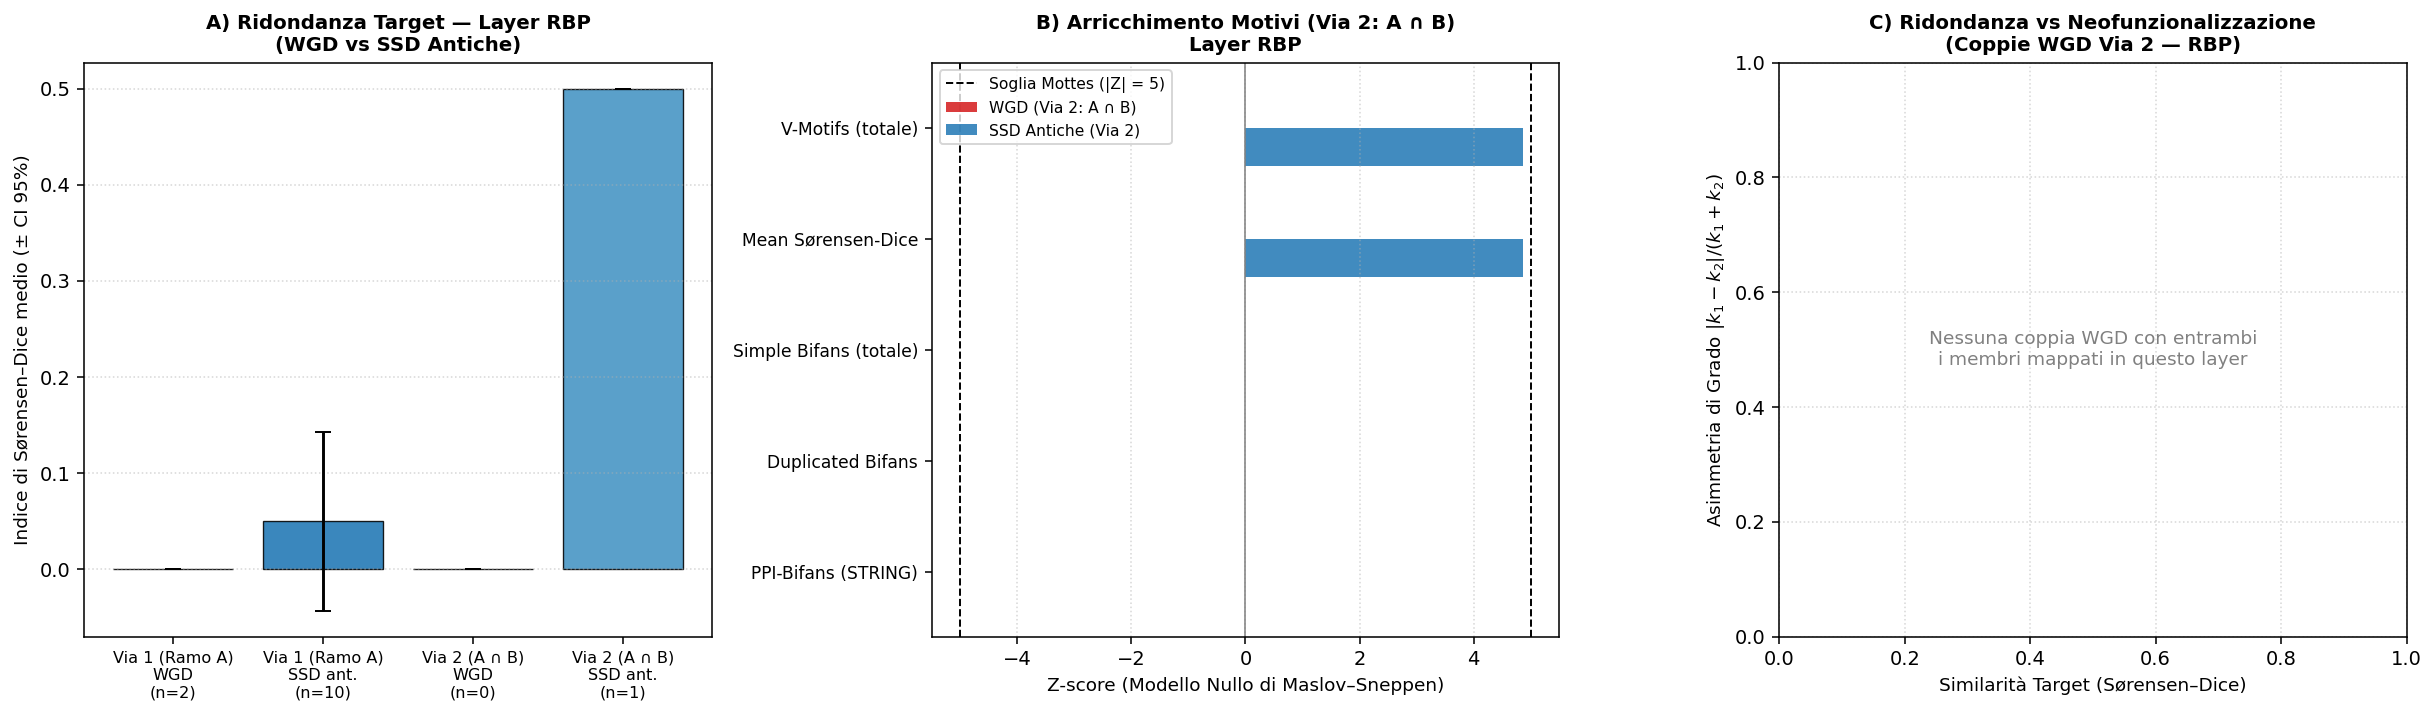

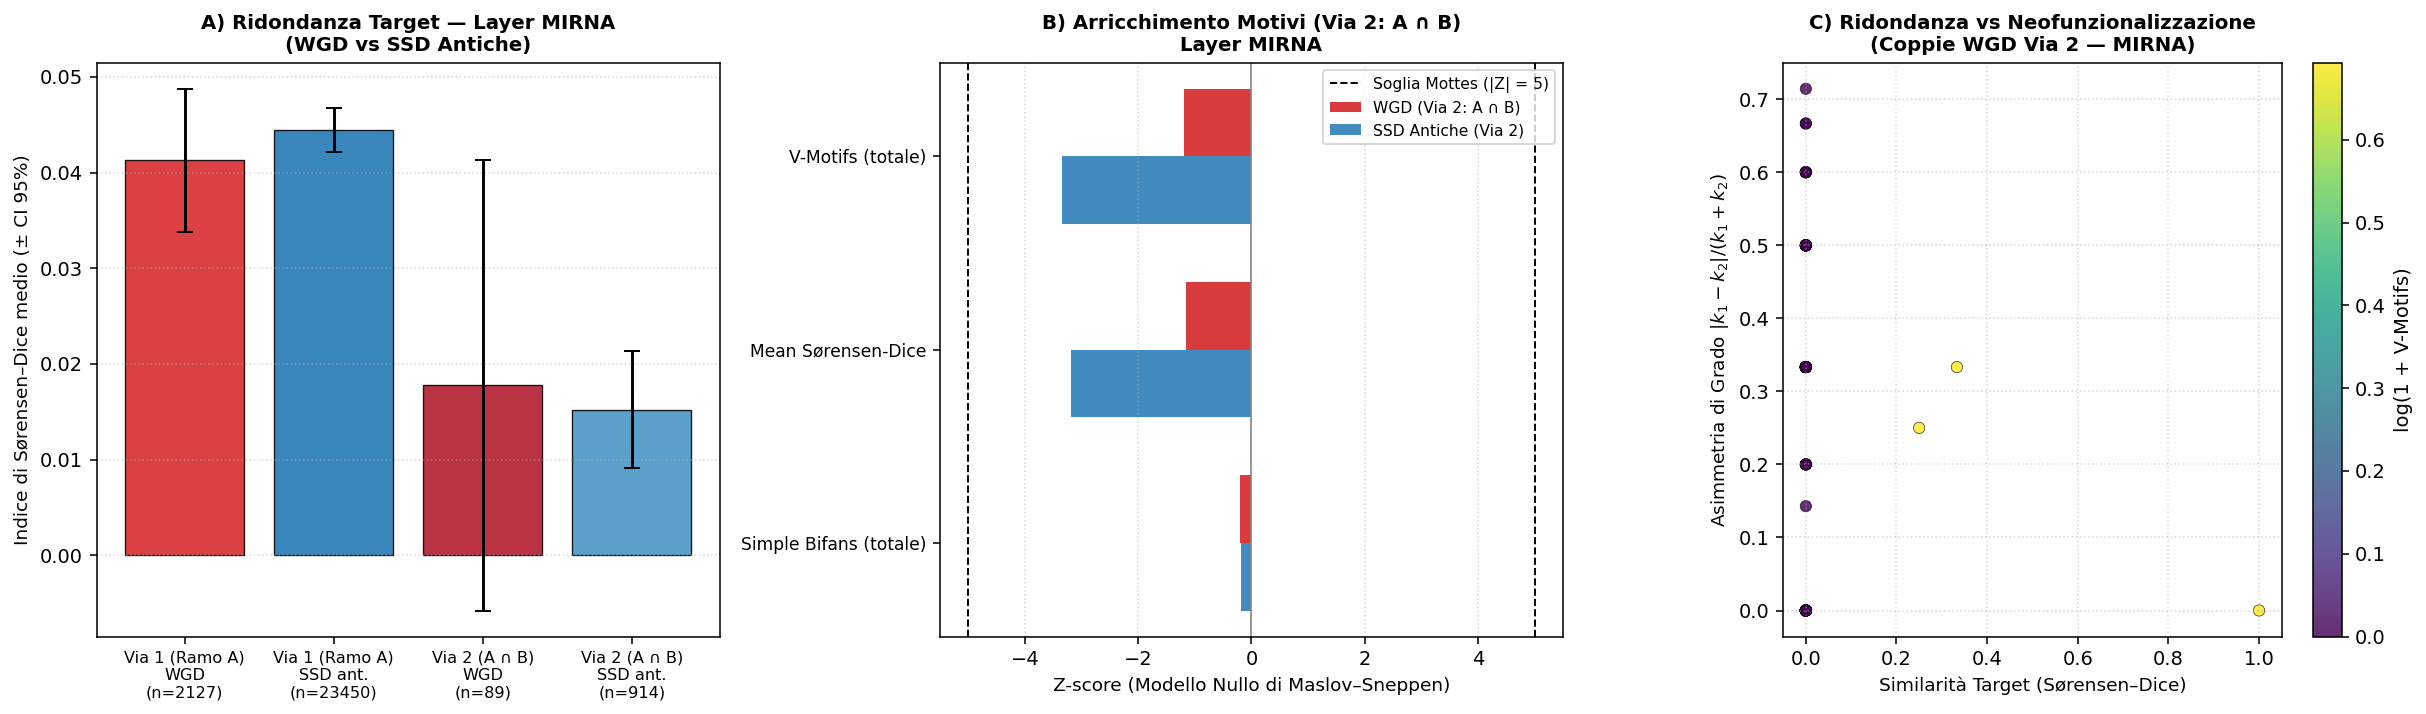

=== TOP 10 COPPIE WGD VIA 2 (A ∩ B) — LAYER miRNA ===


gene_name_1,gene_name_2,lncrna_1,lncrna_2,lncrna_age_1,lncrna_age_2,k_1,k_2,v_motifs,sorensen_dice,simple_bifans,v_motif_pair_z
str,str,str,str,str,str,i64,i64,i64,f64,i64,f64
"""R3HDM1""","""R3HDM2""","""HSALNG0019066""","""HSALNG0091614""","""15. Amniota""","""16. Tetrapoda""",1,1,1,1.0,0,6.965
"""RUNX2""","""RUNX1""","""HSALNG0149159""","""HSALNG0132877""","""15. Amniota""","""16. Tetrapoda""",2,4,1,0.33333,0,2.199
"""SDK1""","""SDK2""","""HSALNG0055800""","""HSALNG0118590""","""15. Amniota""","""15. Amniota""",5,3,1,0.25,0,1.484
"""TNRC18""","""BAHCC1""","""HSALNG0055872""","""HSALNG0119259""","""15. Amniota""","""16. Tetrapoda""",1,1,0,0.0,0,-0.228
"""DST""","""MACF1""","""HSALNG0050796""","""HSALNG0002760""","""17. Euteleostomi""","""16. Tetrapoda""",1,1,0,0.0,0,-0.273
"""ERBB2""","""ERBB3""","""HSALNG0116270""","""HSALNG0091492""","""17. Euteleostomi""","""16. Tetrapoda""",2,1,0,0.0,0,-0.203
"""MYT1""","""ST18""","""HSALNG0131733""","""HSALNG0065254""","""15. Amniota""","""15. Amniota""",1,2,0,0.0,0,-0.175
"""ACTL6A""","""ACTL6B""","""HSALNG0030975""","""HSALNG0060031""","""16. Tetrapoda""","""16. Tetrapoda""",1,1,0,0.0,0,-0.175
"""UNKL""","""UNK""","""HSALNG0108892""","""HSALNG0118787""","""16. Tetrapoda""","""15. Amniota""",3,1,0,0.0,0,-0.251


In [ ]:
# Grafici a 3 pannelli salvati automaticamente in gold/
net_analyzer.plot_phase3_comparison(net_rbp, res_rbp_via1, res_rbp_via2, save_fig=True)
net_analyzer.plot_phase3_comparison(net_mirna, res_mir_via1, res_mir_via2, save_fig=True)

# Top 10 coppie WGD nella Via 2 (A ∩ B) sul Layer RBP (+ STRING PPI-Bifans)
if "WGD" in res_rbp_via2["pair_tables"]:
    print("=== TOP 10 COPPIE WGD VIA 2 (A ∩ B) — LAYER RBP (ordinate per PPI-Bifans) ===")
    display(
        res_rbp_via2["pair_tables"]["WGD"]
        .sort(["ppi_bifans", "sorensen_dice"], descending=True)
        .select([
            "gene_name_1", "gene_name_2", "lncrna_1", "lncrna_2",
            "lncrna_age_1", "lncrna_age_2", "k_1", "k_2",
            "v_motifs", "sorensen_dice", "ppi_bifans", "ppi_bifan_pair_z"
        ])
        .head(10)
    )

# Top 10 coppie WGD nella Via 2 (A ∩ B) sul Layer miRNA
if "WGD" in res_mir_via2["pair_tables"]:
    print("=== TOP 10 COPPIE WGD VIA 2 (A ∩ B) — LAYER miRNA ===")
    display(
        res_mir_via2["pair_tables"]["WGD"]
        .sort(["simple_bifans", "v_motifs", "sorensen_dice"], descending=True)
        .select([
            "gene_name_1", "gene_name_2", "lncrna_1", "lncrna_2",
            "lncrna_age_1", "lncrna_age_2", "k_1", "k_2",
            "v_motifs", "sorensen_dice", "simple_bifans", "v_motif_pair_z"
        ])
        .head(10)
    )

## 7. Discussione dei Risultati della Fase 3

L'analisi topologica e i modelli nulli microcanonici di Maslov–Sneppen condotti in parallelo su due strati molecolari indipendenti (**lncRNA–RBP sperimentale eCLIP + STRING v12.0** e **lncRNA–miRNA tripla intersezione**) e su tutte e tre le vie analitiche delineano un quadro netto e biologicamente coerente:

### 1. Layer lncRNA–miRNA (*ceRNA*): Assenza di Conservazione Sistematica nelle Coppie Intrageniche WGD
A differenza degli ohno-miRNA umani (Agasso et al., 2025) — in cui la conservazione della *seed region* di 6–8 nucleotidi produce un marcato arricchimento di V-motifs e Bifans e una similarità di Sørensen–Dice significativamente superiore nelle coppie WGD rispetto alle SSD — le coppie di **lncRNA intragenici** mostrano una quasi completa divergenza dei siti di legame ai miRNA dopo 500 milioni di anni:
* **Via 2 ($A \cap B$, $\ge 15.\,\text{Amniota}$):** su 89 coppie WGD mappate in rete, solo 3 (3,37%) condividono almeno un miRNA (**$V_{\text{obs}} = 3$** vs $6{,}36 \pm 2{,}82$ nel modello nullo, **$Z = -1{,}19$**, $p = 0{,}28$; **0 Simple Bifans**). Il confronto diretto WGD vs SSD antiche (914 coppie) non mostra alcuna differenza significativa né su Sørensen–Dice ($0{,}0178$ vs $0{,}0152$, Mann–Whitney $p = 0{,}966$) né sull'asimmetria di grado normalizzata $\tilde{\Delta}k$ ($0{,}233$ vs $0{,}242$, $p = 0{,}729$).
* **Via 1 (Ramo A puro):** su 2.127 coppie WGD in rete, il conteggio dei V-motifs è pienamente compatibile con il modello nullo ($128$ vs $125{,}88 \pm 12{,}48$, $Z = +0{,}17$), mentre i Simple Bifans ($4$ vs $0{,}69 \pm 0{,}91$, $Z = +3{,}65$) restano al di sotto della soglia stringente $\vert{}Z\vert{} > 5$ (Mottes et al., 2021).
* **Interpretazione biologica e struttura visiva della figura riassuntiva:** questo risultato offre un riscontro quantitativo diretto alle cautele espresse in letteratura sul modello *ceRNA* come meccanismo generale dei lncRNA: privi di una *seed* rigida, i lncRNA intragenici non vengono trattenuti in coppia come "spugne" ridondanti di miRNA. Nel Pannello A il passaggio dalla Via 1 alla Via 2 dimezza il Sørensen–Dice medio in entrambe le classi (da ~0,041–0,044 a ~0,015–0,018), riflettendo la maggiore divergenza di sequenza delle coppie ancestrali; nel Pannello B le SSD antiche esibiscono persino una moderata deplezione rispetto al modello nullo ($Z = -3{,}34$, $p = 0{,}020$), mentre nel Pannello C emerge una polarizzazione netta con 86/89 coppie WGD sull'asse $S_{\text{SD}} = 0$ e solo tre eccezioni puntuali (**`R3HDM1–R3HDM2`** con $S_{\text{SD}} = 1{,}0$ e $Z_{\text{coppia}} = +6{,}97$, **`RUNX2–RUNX1`** con $S_{\text{SD}} = 0{,}333$ e $Z_{\text{coppia}} = +2{,}20$, e **`SDK1–SDK2`** con $S_{\text{SD}} = 0{,}250$).

### 2. Layer Fisico lncRNA–RBP (+ STRING): Limite di Copertura Intragenica e Segnale PPI-Delta nella Via 3
L'integrazione di `lncrna_rbp_LncBook2.0.csv.gz` (772.745 picchi eCLIP distribuiti su 2.005 geni lncRNA unici) mette in luce una forte asimmetria di annotazione sperimentale: la copertura è compresa tra **0,85% e 1,77%** in tutte le coorti intrageniche, rispetto al **13,07%** nei lincRNA intergenici `17. Euteleostomi`. Questo è un effetto noto delle pipeline eCLIP (in cui i picchi che ricadono negli introni di geni codificanti vengono di norma assegnati al trascritto primario del gene host) e impedisce, usando il solo dataset RBP di LncBook, l'analisi statistica a coppie su Via 1 ($n=2$ WGD) e Via 2 ($n=0$ WGD).

Tuttavia, l'analisi a singolo gene sui motivi **PPI-Delta** (STRING `combined_score >= 700`) nella **Via 3** rivela una netta separazione rispetto al modello nullo di Maslov–Sneppen:
* i 9 geni **`Eut_intragenic_WGD`** presenti nella rete RBP (tra cui `HSALNG0109427` con 14 RBP, `HSALNG0130923` con 10 RBP, `HSALNG0130926` con 9 RBP e l'antisenso `TFAP2A-AS1`) accumulano **62 motivi PPI-Delta** contro $22{,}15 \pm 6{,}60$ attesi (**$Z = +6{,}04$**, sopra la soglia $\vert{}Z\vert{} > 5$);
* al contrario, i 16 **`Eut_intragenic_other`** sono depletati ($1$ vs $18{,}30 \pm 6{,}65$, **$Z = -2{,}60$**), così come il controllo giovane **`1. Homo`** ($720$ vs $945{,}75 \pm 43{,}03$, **$Z = -5{,}25$**). Data la ridotta dimensione campionaria ($N=9$), questo risultato va interpretato come evidenza preliminare da validare su un dataset CLIP-seq più esteso.

### 3. La Scoperta Trasversale della Via 3: Il Regime Topologico dei lincRNA Intergenici Ancestrali
Il risultato più robusto e convergente dell'intera Fase 3 emerge dal confronto tra contesti genomici nella **Via 3 (Ramo B — `17. Euteleostomi`)**: i **635 lincRNA intergenici** presentano una copertura e una connettività ($k_{\text{out}}$) radicalmente superiori rispetto sia ai lncRNA intragenici coevi sia ai controlli giovani, **su entrambi i layer indipendenti**:
* **Layer miRNA:** copertura **63,31%** (vs 39,10% in `Eut_WGD`), $k_{\text{media}} = 3{,}152$ (mediana 2,0) vs $1{,}668$ in `Eut_WGD` (Mann–Whitney $p = 4{,}54 \times 10^{-15}$) e vs $1{,}572$ in `1. Homo` ($p = 3{,}13 \times 10^{-50}$).
* **Layer RBP (eCLIP):** copertura **13,07%** (vs 1,77% in `Eut_WGD`), $k_{\text{media}} = 9{,}108$ (mediana 4,0; 90° percentile 23,0) vs $6{,}102$ (mediana 2,0) in `1. Homo` (Mann–Whitney $p = 0{,}0040$; KS $p = 0{,}0068$).

Ciò dimostra che i lincRNA intergenici ancestrali costituiscono il nucleo ad alta connettività delle reti di interazione RNA–RNA e RNA–proteina, confermando il valore dell'architettura a tre vie adottata in questo studio.

## 8. Conclusioni

La Fase 3 stabilisce tre punti fermi sulla topologia delle reti regolatorie dei lncRNA umani:

1. **Superamento dell'analogia naïf con i miRNA (*ceRNA*):** sebbene la Fase 2 abbia dimostrato una ritenzione preferenziale delle coppie di lncRNA intragenici nei geni host WGD ($\text{OR}_{\text{adj}}$ fino a $1{,}41$), la Fase 3 dimostra tramite modelli nulli di Maslov–Sneppen che tale ritenzione **non è accompagnata da una conservazione sistematica di V-motifs o Bifans nel layer lncRNA–miRNA** ($Z = -1{,}19$ nella Via 2; $p = 0{,}97$ WGD vs SSD). Eventuali meccanismi funzionali comuni degli ohno-lncRNA intragenici vanno dunque cercati altrove (regolazione trascrizionale *in cis*, interazione con complessi proteici, co-espressione tissutale).
2. **Segnale preliminare nel layer fisico RBP + STRING e limite di copertura:** i lncRNA ancestrali in host WGD mappati in eCLIP mostrano un forte arricchimento di motivi **PPI-Delta** ($Z = +6{,}04$) in netto contrasto con gli intragenici non-WGD ($Z = -2{,}60$) e i lncRNA `1. Homo` ($Z = -5{,}25$), ma la bassa copertura intragenica del file RBP di LncBook v2.0 (2.005 geni totali) impedisce ancora il test statistico dei PPI-Bifans a coppie.
3. **Centralità topologica dei lincRNA intergenici antichi (Via 3):** su entrambi i layer di interazione (miRNA e RBP), i lincRNA intergenici emersi al nodo `17. Euteleostomi` mostrano una densità di interazioni significativamente superiore a quella di tutte le coorti intrageniche e dei controlli recenti ($p = 4{,}5 \times 10^{-15}$ su miRNA; $p = 0{,}004$ su RBP).

## 9. Prossimi Passi $\to$ Notebook 04 (`04_expression_epigenetics_robustness.ipynb`) & Futura Estensione CLIP-seq

Alla luce dei risultati della Fase 3 — in cui la ritenzione evolutiva degli ohno-lncRNA intragenici non si spiega tramite ridondanza di legame ai miRNA — il **Notebook 04 (Fase 4)** sposterà il focus sulla **dinamica di espressione e sui layer multi-omici già presenti in `silver/`**:
1. **Livelli di espressione tissutale e ampiezza di espressione** (replicando la Fig. 7 di Agasso et al., 2025 tramite `lncbook_expression.parquet`): verificare se i lncRNA WGD (Via 1 e Via 2) e la coorte `17. Euteleostomi` (Via 3) sono più espressi e più ubiquitari rispetto ai controlli SSD e recenti.
2. **Divergenza vs co-espressione nelle coppie duplicate:** calcolo della distanza **$1 - \text{Cosine Similarity}$** (Agasso et al., Fig. 5D) e della correlazione di Spearman tra i profili tissutali delle coppie WGD rispetto alle SSD antiche, per quantificare **subfunzionalizzazione tissutale** vs co-espressione conservata.
3. **Controlli multi-omici integrativi (LncBook v2.0):** analisi del potenziale codificante nascosto (`lncbook_sprotein.parquet`) e del profilo epigenetico dei promotori (`lncbook_methylation.parquet`) sulle 3 vie.
4. **Estensione futura (dopo la Fase 4):** integrazione di un database CLIP-seq più esteso (es. **ENCORI/starBase** o **NPInter v5**) per sbloccare la copertura RBP sulle coppie intrageniche (Via 1 e Via 2) e integrazione di **NONCODE v7** per la validazione a singola cellula.